In [1]:
!pip install tensorflow numpy pandas pillow requests tqdm

Defaulting to user installation because normal site-packages is not writeable


In [1]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from io import BytesIO
import requests
from tqdm.auto import tqdm
import warnings
import time
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model

In [2]:
# load the cleaned data
test_df = pd.read_csv('final_dataset_preprocessed.csv')

In [3]:
# shape
print("Shape of the dataset:", test_df.shape)

Shape of the dataset: (40301, 51)


In [4]:
# Config
CSV_PATH = "./final_dataset_preprocessed.csv"
ID_COLUMN = "id"
URL_COLUMN = "photo_1536x864"

OUT_DIR = "./image_embeddings_final_new"

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
DOWNLOAD_WORKERS = 8

USER_AGENT = "Mozilla/5.0 (compatible; ImageDownloader/1.0)"

os.makedirs(OUT_DIR, exist_ok=True)

# Load Dataset
df = pd.read_csv(CSV_PATH)
N = len(df)

print(f"Loaded dataset: {N} rows")

Loaded dataset: 40301 rows


In [ ]:
# Persistent HTTP Session
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})

# Image Downloader
def download_and_preprocess(url):

    if not url or str(url).lower() == "nan":
        return None

    try:
        time.sleep(0.05)
        resp = session.get(url, timeout=10)
        resp.raise_for_status()

        img = Image.open(BytesIO(resp.content)).convert("RGB")
        img = img.resize(TARGET_SIZE, Image.LANCZOS)

        arr = np.array(img, dtype=np.uint8)

        if arr.shape != (*TARGET_SIZE, 3):
            arr = arr[:, :, :3]

        return arr

    except Exception:
        return None

# ResNet Model
def create_resnet_encoder():

    tf.keras.backend.clear_session()

    input_shape = (224, 224, 3)
    img_input = Input(shape=input_shape)

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_tensor=img_input,
        pooling="avg"
    )

    return Model(inputs=img_input, outputs=base_model.output)

resnet_encoder = create_resnet_encoder()
print("ResNet encoder ready")

# Memory Map Storage
RESNET_DIM = 2048

# Define file paths for memmaps
resnet_file = os.path.abspath(
    os.path.join(OUT_DIR, "resnet_embeddings.dat")
)

# Function to create or open memmap
def create_memmap(file_path, shape, dtype="float32"):

    if os.path.exists(file_path):
        print(f"Opening existing memmap: {os.path.basename(file_path)}")
        return np.memmap(file_path, dtype=dtype, mode="r+", shape=shape)

    print(f"Creating memmap: {os.path.basename(file_path)}")
    return np.memmap(file_path, dtype=dtype, mode="w+", shape=shape)

resnet_memmap = create_memmap(resnet_file, (N, RESNET_DIM))

# Index Map
index_map = pd.DataFrame({
    "orig_index": np.arange(N),
    "url": df[URL_COLUMN],
    "status": "not_processed"
})

# Batch Processing
def process_batch(indices_in_batch):

    urls = [df[URL_COLUMN].iloc[idx] for idx in indices_in_batch]

    # Parallel downloads
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as executor:
        results = list(executor.map(download_and_preprocess, urls))

    batch_imgs = []
    valid_indices = []

    for idx, arr in zip(indices_in_batch, results):

        if arr is not None:
            batch_imgs.append(arr)
            valid_indices.append(idx)

    if not batch_imgs:
        return [], []

    batch_raw = np.stack(batch_imgs).astype(np.float32)

    batch_resnet = resnet_preprocess(batch_raw)

    emb_resnet = resnet_encoder.predict(batch_resnet, verbose=0)

    return valid_indices, emb_resnet

# Main Loop
all_indices = np.arange(N)

for start in tqdm(range(0, N, BATCH_SIZE)):
    end = min(start + BATCH_SIZE, N)
    indices_in_batch = all_indices[start:end]

    valid_indices, emb_res = process_batch(indices_in_batch)

    if len(valid_indices) > 0:
        resnet_memmap[valid_indices, :] = emb_res
        
        # Mark as OK
        index_map.loc[valid_indices, "status"] = "ok"

    # Mark failures
    failed_in_batch = [i for i in indices_in_batch if i not in valid_indices]
    if failed_in_batch:
        index_map.loc[failed_in_batch, "status"] = "failed"

    # Periodic Flush (Save progress to disk every 50 batches)
    if (start // BATCH_SIZE) % 50 == 0:
        resnet_memmap.flush()

# Flush Memory Map
resnet_memmap.flush()
del resnet_memmap

index_map.to_csv(
    os.path.join(OUT_DIR, "index_map.csv"),
    index=False
)

print("ResNet embeddings saved.")

Loaded dataset: 40301 rows
ResNet encoder ready ✅
Creating memmap: resnet_embeddings.dat


100%|██████████| 1260/1260 [34:39<00:00,  1.65s/it]


Done ✅ ResNet embeddings saved.


In [10]:
EMB_PATH = "./image_embeddings_final_new/resnet_embeddings.dat"
INDEX_MAP_PATH = "./image_embeddings_final_new/index_map.csv"

df = pd.read_csv(CSV_PATH)
index_map = pd.read_csv(INDEX_MAP_PATH)

N = len(df)
RESNET_DIM = 2048

resnet_embeddings = np.memmap(
    EMB_PATH,
    dtype="float32",
    mode="r",
    shape=(N, RESNET_DIM)
)

print("Dataset rows:", len(df))
print("Index map rows:", len(index_map))

Dataset rows: 40301
Index map rows: 40301


In [6]:
print((index_map["orig_index"] == df.index).all())

True


In [11]:
index_map["status"].value_counts()

status
ok        40296
failed        5
Name: count, dtype: int64

In [8]:
for i in range(1000):
    print(i, resnet_embeddings[i][:5])

0 [0.        0.        0.0341902 0.        0.5701932]
1 [0.05249826 0.36543873 0.1137852  3.8598254  0.31524527]
2 [0.15428953 0.23312093 0.02148407 1.3110514  0.2973685 ]
3 [0.01822334 0.06876101 0.         0.13930836 0.03494077]
4 [0.34356406 0.51892495 0.31952414 1.8141632  0.1359049 ]
5 [0.1470689  0.03081559 0.         4.681806   0.35102275]
6 [1.8503096  0.11371218 0.00186088 1.4245845  1.0651169 ]
7 [1.0153854  0.42978767 0.3504874  0.5276194  0.1376868 ]
8 [1.2426808  1.6690067  0.16084102 0.21734913 0.30813134]
9 [0.46836972 0.45872456 0.18916093 2.0176547  0.18157773]
10 [0.15514183 0.05726178 0.762323   0.         0.32813862]
11 [0.29173246 0.02048969 0.03802873 1.2577585  0.02391247]
12 [0.00745821 0.7107038  0.         1.4070598  0.06700893]
13 [6.7776680e-02 2.7994173e+00 1.4813445e-03 3.4452960e-01 1.2141513e-02]
14 [0.35719082 2.7679548  0.90144116 0.02617992 0.03723063]
15 [0.08508389 1.3926377  0.02308002 0.37793973 0.07984731]
16 [0.0326182  0.12867531 0.39912742 0.0

In [12]:
zero_rows = np.where(np.all(resnet_embeddings == 0, axis=1))[0]

print("Zero embedding rows:", len(zero_rows))

Zero embedding rows: 5


In [13]:
failed = (index_map["status"] == "failed").sum()

print("Failed downloads:", failed)
print("Zero embeddings:", zero_rows)

Failed downloads: 5
Zero embeddings: [ 6825 15173 25127 31495 35497]


In [14]:
emb = resnet_embeddings[~np.all(resnet_embeddings == 0, axis=1)]

print("Mean:", emb.mean())
print("Std:", emb.std())
print("Min:", emb.min())
print("Max:", emb.max())

Mean: 0.4878764
Std: 0.82876676
Min: 0.0
Max: 40.437805


In [15]:
sample = emb[:1000]

unique_rows = np.unique(sample, axis=0).shape[0]

print("Unique vectors in first 1000:", unique_rows)

Unique vectors in first 1000: 1000


In [16]:
norms = np.linalg.norm(emb[:5000], axis=1)

print("Mean norm:", norms.mean())
print("Std norm:", norms.std())

Mean norm: 43.185974
Std norm: 6.239321


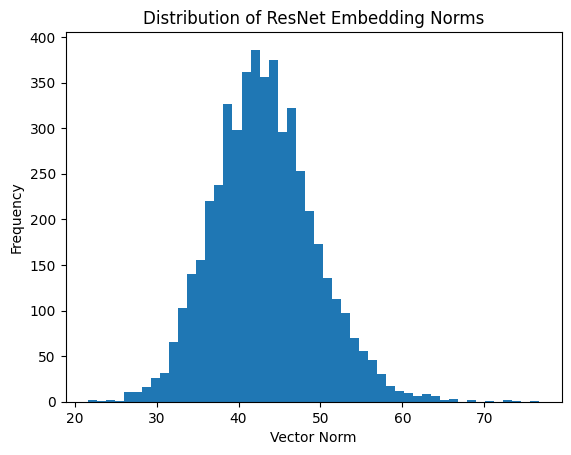

In [17]:
norms = np.linalg.norm(emb[:5000], axis=1)

plt.hist(norms, bins=50)
plt.title("Distribution of ResNet Embedding Norms")
plt.xlabel("Vector Norm")
plt.ylabel("Frequency")
plt.show()

In [18]:
resnet_memmap = np.memmap(EMB_PATH, dtype="float32", mode="r", shape=(N, RESNET_DIM))
zero_rows = np.where(np.all(resnet_memmap == 0, axis=1))[0]
print(len(zero_rows))

5


In [19]:
i = 100

print("Index:", i)
print("Image URL:", df.loc[i, "photo_1536x864"])
print("Embedding first values:", resnet_embeddings[i][:10])

Index: 100
Image URL: https://i.kickstarter.com/assets/011/943/099/608432148bd7b93cd3d345dcf79bbe34_original.jpg?anim=false&fit=cover&gravity=auto&height=873&origin=ugc&q=92&v=1463718414&width=1552&sig=kZKhZZjQIHwRPOXRZdRrlZYc%2BwgfjgI4c%2FuEr7zVkzg%3D
Embedding first values: [1.04228    3.3887312  0.00451224 1.1770169  0.32059953 0.47312662
 0.18367742 0.7236508  2.1874015  0.        ]
